In [1]:
import pandas as pd
import matplotlib.pyplot as plt

print("Retail Sales Analysis")

Retail Sales Analysis


In [2]:
df = pd.read_excel("../data/sample_-_superstore.xls")

print("Jumlah baris dan kolom:", df.shape)
df.head()

Jumlah baris dan kolom: (10194, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,US-2023-103800,2023-01-03,2023-01-07,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,...,77095,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512
1,2,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870
2,3,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.784,3,0.2,4.2717
3,4,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748
4,5,US-2023-141817,2023-01-05,2023-01-12,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,...,19143,East,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840


In [3]:
# Melihat seluruh nama kolom
print(df.columns.tolist())

['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country/Region', 'City', 'State/Province', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']


In [4]:
for kolom in df.columns:
    print(kolom)

Row ID
Order ID
Order Date
Ship Date
Ship Mode
Customer ID
Customer Name
Segment
Country/Region
City
State/Province
Postal Code
Region
Product ID
Category
Sub-Category
Product Name
Sales
Quantity
Discount
Profit


In [5]:
# Melihat informasi dataset
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 10194 entries, 0 to 10193
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Row ID          10194 non-null  int64         
 1   Order ID        10194 non-null  str           
 2   Order Date      10194 non-null  datetime64[us]
 3   Ship Date       10194 non-null  datetime64[us]
 4   Ship Mode       10194 non-null  str           
 5   Customer ID     10194 non-null  str           
 6   Customer Name   10194 non-null  str           
 7   Segment         10194 non-null  str           
 8   Country/Region  10194 non-null  str           
 9   City            10194 non-null  str           
 10  State/Province  10194 non-null  str           
 11  Postal Code     10194 non-null  object        
 12  Region          10194 non-null  str           
 13  Product ID      10194 non-null  str           
 14  Category        10194 non-null  str           
 15  Sub-Category 

In [6]:
df.describe()

,Row ID,Order Date,Ship Date,Sales,Quantity,Discount,Profit
count,10194.000000,10194,10194,10194.000000,10194.000000,10194.000000,10194.000000
mean,5097.500000,2025-04-29 11:48:25.002943,2025-05-03 10:52:45.626839,228.225854,3.791838,0.155385,28.673417
min,1.000000,2023-01-03 00:00:00,2023-01-07 00:00:00,0.444000,1.000000,0.000000,-6599.978000
25%,2549.250000,2024-05-14 00:00:00,2024-05-19 00:00:00,17.220000,2.000000,0.000000,1.760800
50%,5097.500000,2025-06-25 00:00:00,2025-06-28 00:00:00,53.910000,3.000000,0.200000,8.690000
75%,7645.750000,2026-05-14 00:00:00,2026-05-18 00:00:00,209.500000,5.000000,0.200000,29.297925
max,10194.000000,2026-12-30 00:00:00,2027-01-05 00:00:00,22638.480000,14.000000,0.800000,8399.976000
std,2942.898656,NaN,NaN,619.906839,2.228317,0.206249,232.465115


In [7]:
# Mengecek data kosong
print("Data kosong:")
print(df.isnull().sum())

# Mengecek data duplikat
print("\nJumlah data duplikat:")
print(df.duplicated().sum())

Data kosong:
Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country/Region    0
City              0
State/Province    0
Postal Code       0
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
Quantity          0
Discount          0
Profit            0
dtype: int64

Jumlah data duplikat:
0


In [8]:
# Total penjualan berdasarkan kategori
sales_category = df.groupby('Category')['Sales'].sum()

# Urutkan dari penjualan terbesar
sales_category = sales_category.sort_values(ascending=False)

print(sales_category)

Category
Technology         839893.2790
Furniture          754747.7613
Office Supplies    731893.3140
Name: Sales, dtype: float64


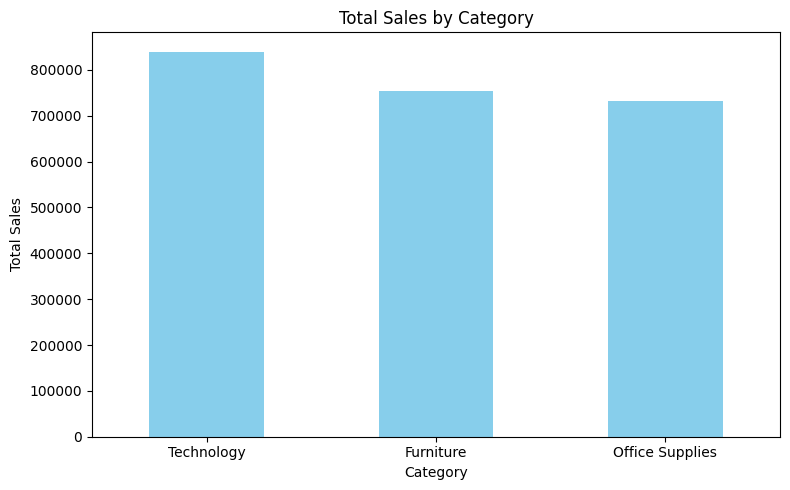

In [9]:
# Visualisasi total penjualan berdasarkan kategori
sales_category.plot(
    kind='bar',
    figsize=(8, 5),
    title='Total Sales by Category',
    color='skyblue'
)

plt.xlabel('Category')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [10]:
# Menghitung total profit berdasarkan kategori
profit_category = df.groupby('Category')['Profit'].sum()

# Mengurutkan dari profit terbesar
profit_category = profit_category.sort_values(ascending=False)

print(profit_category)

Category
Technology         146543.3756
Office Supplies    126023.4434
Furniture           19729.9956
Name: Profit, dtype: float64


In [11]:
profit_subcategory = df.groupby('Sub-Category')['Profit'].sum().sort_values(ascending=False)

print(profit_subcategory)

Sub-Category
Copiers        56093.9365
Phones         45050.8265
Accessories    41936.6357
Paper          34511.5070
Binders        31426.1003
Chairs         27223.5323
Storage        21285.1115
Appliances     18329.4844
Furnishings    13891.7430
Envelopes       6988.0247
Art             6653.1962
Labels          5572.7780
Machines        3461.9769
Fasteners       2428.6358
Supplies       -1171.3945
Bookcases      -3632.0736
Tables        -17753.2061
Name: Profit, dtype: float64


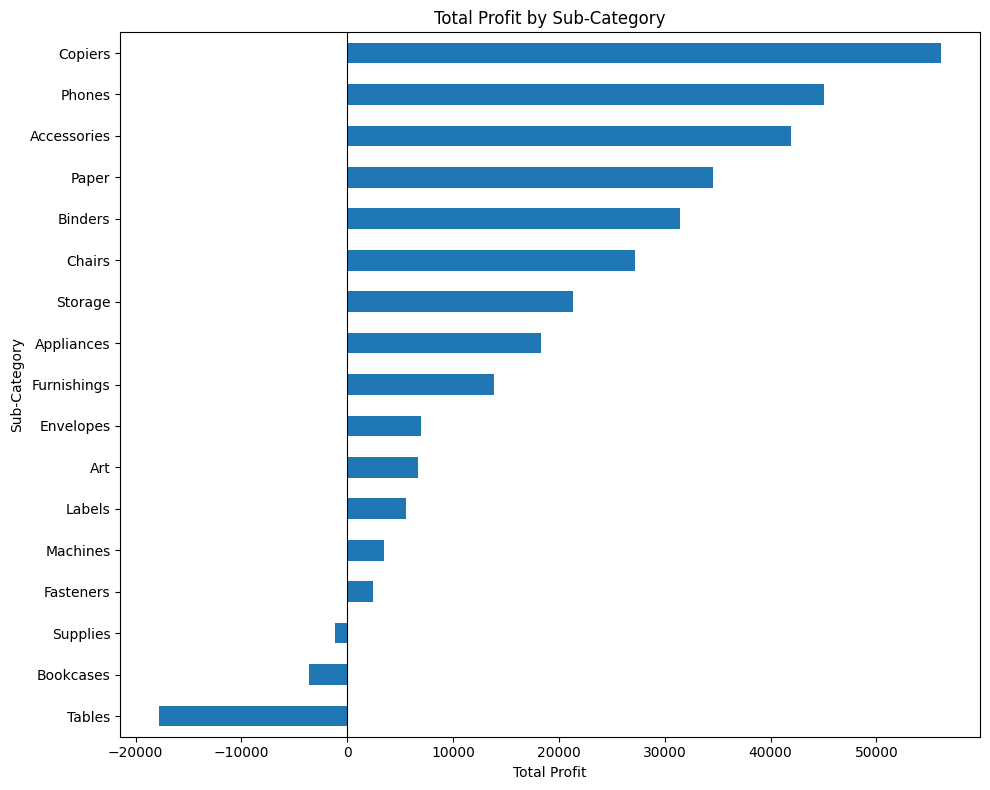

In [12]:
# Visualisasi profit berdasarkan sub-category
profit_subcategory.sort_values().plot(
    kind='barh',
    figsize=(10, 8),
    title='Total Profit by Sub-Category'
)

plt.xlabel('Total Profit')
plt.ylabel('Sub-Category')
plt.axvline(x=0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()

In [13]:
# Menganalisis penjualan, profit, dan diskon
discount_analysis = df.groupby('Sub-Category').agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Average_Discount=('Discount', 'mean')
)

# Mengurutkan berdasarkan profit terendah
discount_analysis = discount_analysis.sort_values(
    by='Total_Profit'
)

display(discount_analysis.round(2))


,Total_Sales,Total_Profit,Average_Discount
Sub-Category,,,
Tables,208020.18,-17753.21,0.26
Bookcases,115361.20,-3632.07,0.22
Supplies,46725.50,-1171.39,0.08
Fasteners,8532.24,2428.64,0.08
Machines,189925.03,3461.98,0.30
Labels,12695.04,5572.78,0.07
Art,27659.01,6653.20,0.08
Envelopes,16528.36,6988.02,0.08
Furnishings,95598.13,13891.74,0.14


In [14]:
discount_impact = df.groupby('Discount').agg(
    Total_Transaksi=('Row ID', 'count'),
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Rata_Rata_Profit=('Profit', 'mean')
)

display(discount_impact.round(2))

,Total_Transaksi,Total_Sales,Total_Profit,Rata_Rata_Profit
Discount,,,,
0.00,4925,1105323.79,326718.59,66.34
0.10,96,54952.50,9099.97,94.79
0.15,52,27558.52,1418.99,27.29
0.20,3706,773939.40,91079.95,24.58
0.30,230,104474.07,-10513.45,-45.71
0.32,27,14493.46,-2391.14,-88.56
0.40,207,116497.76,-23086.37,-111.53
0.45,11,5484.97,-2493.11,-226.65
0.50,66,58918.54,-20506.43,-310.70


In [15]:
# Memfilter transaksi khusus kategori Tables
tables_data = df[df['Sub-Category'] == 'Tables']

# Menganalisis profit berdasarkan tingkat diskon
tables_discount = tables_data.groupby('Discount').agg(
    Jumlah_Baris=('Row ID', 'count'),
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Rata_Rata_Profit=('Profit', 'mean')
)

display(tables_discount.round(2))

,Jumlah_Baris,Total_Sales,Total_Profit,Rata_Rata_Profit
Discount,,,,
0.00,76,71706.23,13334.92,175.46
0.20,72,45636.58,-298.40,-4.14
0.30,56,25902.98,-3493.84,-62.39
0.40,75,45614.41,-16187.40,-215.83
0.45,11,5484.97,-2493.11,-226.65
0.50,36,13675.01,-8615.39,-239.32


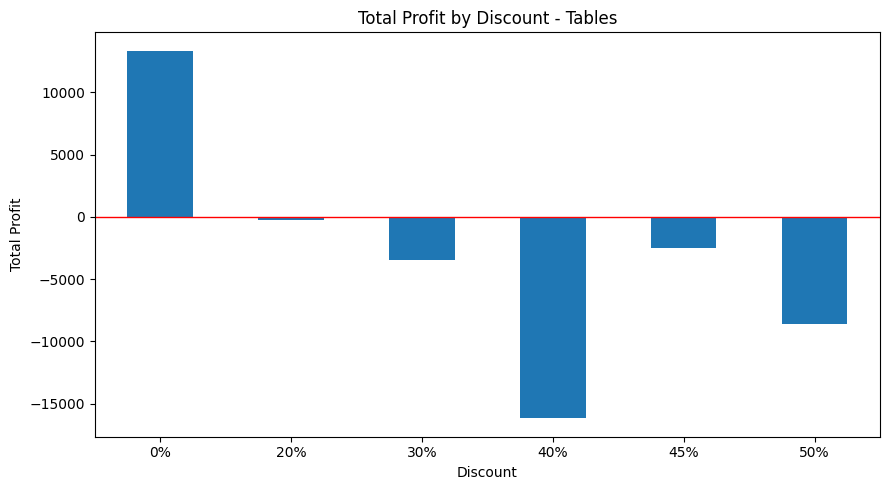

In [16]:
# Visualisasi profit Tables berdasarkan diskon
tables_discount['Total_Profit'].plot(
    kind='bar',
    figsize=(9, 5),
    title='Total Profit by Discount - Tables'
)

plt.axhline(y=0, color='red', linewidth=1)
plt.xlabel('Discount')
plt.ylabel('Total Profit')
plt.xticks(
    range(len(tables_discount)),
    [f'{x:.0%}' for x in tables_discount.index],
    rotation=0
)
plt.tight_layout()
plt.show()


# Business Insights

## 1. Analisis Penjualan Berdasarkan Kategori
Kategori Technology memiliki total penjualan tertinggi sebesar 839.893,28. Selanjutnya Furniture sebesar 754.747,76 dan Office Supplies sebesar 731.893,31.

## 2. Analisis Profit Berdasarkan Kategori
Technology menghasilkan profit tertinggi sebesar 146.543,38, sedangkan Furniture hanya menghasilkan 19.729,99. Hal ini menunjukkan bahwa penjualan yang tinggi belum tentu menghasilkan keuntungan yang sebanding.

## 3. Analisis Profit Berdasarkan Sub-Category
Copiers menjadi sub-category dengan profit tertinggi sebesar 56.093,94. Sebaliknya, Tables mengalami kerugian terbesar sebesar 17.753,21.

## 4. Analisis Diskon
Pada kategori Tables, transaksi tanpa diskon menghasilkan total profit positif sebesar 13.334,92. Sementara itu, transaksi dengan diskon 20% sampai 50% secara keseluruhan menghasilkan profit negatif.

Temuan ini menunjukkan adanya hubungan antara pemberian diskon dan rendahnya profit pada kategori Tables. Namun, faktor lain seperti harga pokok, harga jual, dan karakteristik produk juga perlu diperiksa.

# Business Recommendations

1. Evaluasi kebijakan diskon untuk kategori Tables, terutama diskon 30% sampai 50%.
2. Periksa struktur harga dan biaya produk Tables untuk mengetahui penyebab kerugian.
3. Pertahankan strategi penjualan produk yang memberikan profit tinggi, seperti Copiers, Phones, dan Accessories.
4. Jangan hanya menggunakan total Sales sebagai ukuran keberhasilan. Profit juga perlu menjadi indikator utama.
5. Lakukan evaluasi profit secara berkala berdasarkan kategori, sub-category, dan tingkat diskon.

# Conclusion

Berdasarkan analisis 10.194 baris transaksi, Technology menjadi kategori dengan penjualan dan profit tertinggi. Sementara itu, Tables menjadi salah satu area yang perlu mendapat perhatian karena menghasilkan kerugian terbesar pada tingkat sub-category.

Analisis ini menunjukkan bahwa keputusan bisnis sebaiknya tidak hanya berfokus pada peningkatan penjualan, tetapi juga memperhatikan profitabilitas dan efektivitas pemberian diskon.
